In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("./dataset/train.csv")

#### Initial Understanding about the Dataset

In [3]:
df.sample(10)

,No,ID,Weight,Fat,Visibility,Category,Price,Security,StoreCode,OperationYear,Size,Area,Type,Sales
7034,7035,DRH37,17.60,Low Fat,0.041681,Soft Drinks,164.2526,Prosegur,OUT049,1999,Medium,Tier 1,Supermarket Type1,1315.6208
1672,1673,FDH08,7.51,Low Fat,0.017429,Fruits and Vegetables,229.6010,NSPS,OUT046,1997,Small,Tier 1,Supermarket Type1,6201.9270
2610,2611,DRH25,18.70,Low Fat,0.000000,Soft Drinks,52.2324,Allied Universal,OUT035,2004,Small,Tier 2,Supermarket Type1,467.3916
4573,4574,FDA21,13.65,Low Fat,0.035961,Snack Foods,186.3924,G4S,OUT046,1997,Small,Tier 1,Supermarket Type1,1665.8316
4619,4620,FDY48,NaN,Low Fat,0.041557,Baking Goods,104.4332,AHS,OUT019,1985,Small,Tier 1,Grocery Store,307.5996
5731,5732,FDV35,19.50,Low Fat,0.128728,Breads,155.3314,Epic,OUT018,2009,Medium,Tier 3,Supermarket Type2,3412.8908
4070,4071,FDW24,6.80,Low Fat,0.037466,Baking Goods,47.5034,Brinks,OUT013,1987,High,Tier 3,Supermarket Type1,534.6374
7037,7038,NCC19,6.57,Low Fat,0.096881,Household,191.4820,AHS,OUT046,1997,Small,Tier 1,Supermarket Type1,5020.1320
922,923,FDO49,NaN,Regular,0.057870,Breakfast,49.7008,AHS,OUT019,1985,Small,Tier 1,Grocery Store,50.6008
4972,4973,FDD02,16.60,Low Fat,0.050369,Canned,117.2124,AHS,OUT049,1999,Medium,Tier 1,Supermarket Type1,1422.1488


In [4]:
pd.set_option("display.float_format", "{:.2f}".format)
df.describe()

,No,Weight,Visibility,Price,OperationYear,Sales
count,8540.00,7074.00,8540.00,8540.00,8540.00,8540.00
mean,4270.50,36.90,9072.74,5004.09,1998.01,26730.40
std,2465.43,2004.87,838424.94,386410.25,20.06,1383157.72
min,1.00,-87523.00,0.00,-13479.00,1876.00,-7976.73
25%,2135.75,8.77,0.03,93.80,1987.00,830.92
50%,4270.50,12.60,0.05,143.03,1999.00,1794.33
75%,6405.25,16.85,0.09,185.76,2004.00,3101.30
max,8540.00,98032.00,77480627.00,35127361.00,3678.00,99999999.00


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8540 entries, 0 to 8539
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   No             8540 non-null   int64  
 1   ID             8540 non-null   object 
 2   Weight         7074 non-null   float64
 3   Fat            8540 non-null   object 
 4   Visibility     8540 non-null   float64
 5   Category       8540 non-null   object 
 6   Price          8540 non-null   float64
 7   Security       8540 non-null   object 
 8   StoreCode      8540 non-null   object 
 9   OperationYear  8540 non-null   int64  
 10  Size           6125 non-null   object 
 11  Area           8540 non-null   object 
 12  Type           8540 non-null   object 
 13  Sales          8540 non-null   float64
dtypes: float64(4), int64(2), object(8)
memory usage: 934.2+ KB


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df["ID"].unique().size

1562

In [8]:
df["Fat"].unique()

array(['Low Fat', 'Regular', 'low fat', 'LF', 'reg'], dtype=object)

In [9]:
df["Category"].unique()

array(['Dairy', 'Soft Drinks', 'Meat', 'Fruits and Vegetables',
       'Household', 'Baking Goods', 'Snack Foods', 'Frozen Foods',
       'Breakfast', 'Health and Hygiene', 'Hard Drinks', 'Canned',
       'Breads', 'Starchy Foods', 'Others', 'Seafood'], dtype=object)

In [10]:
df["Size"].unique()

array(['Medium', nan, 'High', 'Small'], dtype=object)

In [11]:
df["Area"].unique()

array(['Tier 1', 'Tier 3', 'Tier 2'], dtype=object)

In [12]:
df["Type"].unique()

array(['Supermarket Type1', 'Supermarket Type2', 'Grocery Store',
       'Supermarket Type3'], dtype=object)

In [13]:
df["StoreCode"].unique()

array(['OUT049', 'OUT018', 'OUT010', 'OUT013', 'OUT027', 'OUT045',
       'OUT017', 'OUT046', 'OUT035', 'OUT019'], dtype=object)

#### Preprocessing of Sales Column (Target)

In [14]:
df["Sales"].describe()

count       8540.00
mean       26730.40
std      1383157.72
min        -7976.73
25%          830.92
50%         1794.33
75%         3101.30
max     99999999.00
Name: Sales, dtype: float64

In [15]:
df=df[df["Sales"]>0]

<Axes: ylabel='Sales'>

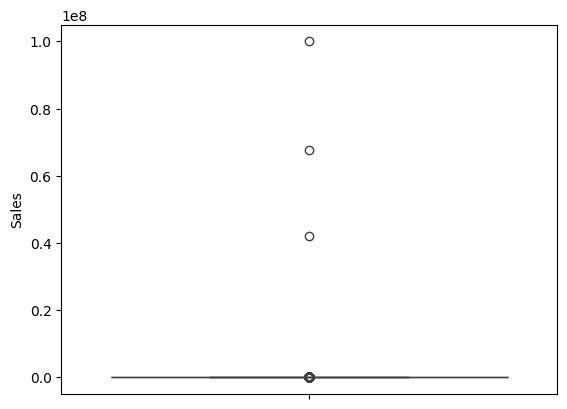

In [16]:
sns.boxplot(df["Sales"])

In [17]:
df.nlargest(10, "Sales")[["Sales"]]

,Sales
5180,99999999.00
6047,67612861.00
6193,42079856.00
7202,13086.96
5233,12117.56
1453,11445.10
4357,10993.69
6554,10306.58
4897,10256.65
1012,10236.67


In [18]:
df.loc[[5180, 6047, 6193]]

,No,ID,Weight,Fat,Visibility,Category,Price,Security,StoreCode,OperationYear,Size,Area,Type,Sales
5180,5181,FDY90,-7832.00,Regular,0.08,Fruits and Vegetables,6423746.00,Brinks,OUT049,1999,Medium,Tier 1,Supermarket Type1,99999999.00
6047,6048,FDM24,98032.00,Regular,0.08,Baking Goods,35127361.00,Allied Universal,OUT035,2004,Small,Tier 2,Supermarket Type1,67612861.00
6193,6194,FDF39,14.85,Regular,0.02,Dairy,263.79,Epic,OUT045,2002,NaN,Tier 2,Supermarket Type1,42079856.00


In [19]:
df = df.drop(index=[5180, 6047, 6193])

### Exploratory Data Analysis

#### Univariate Analysis

<Axes: xlabel='ID', ylabel='Count'>

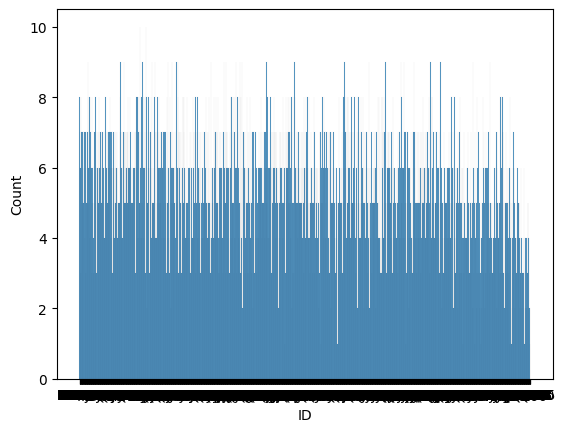

In [20]:
sns.histplot(df["ID"], bins=10)

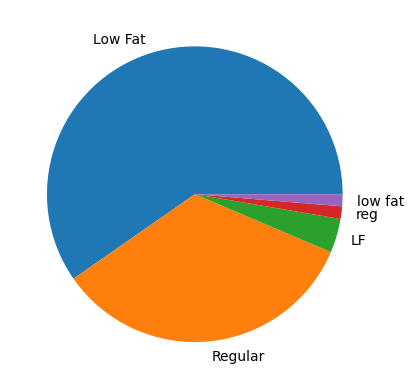

In [21]:
plt.pie(df["Fat"].value_counts(), labels=df["Fat"].value_counts().index)
plt.show()

<Axes: xlabel='OperationYear', ylabel='count'>

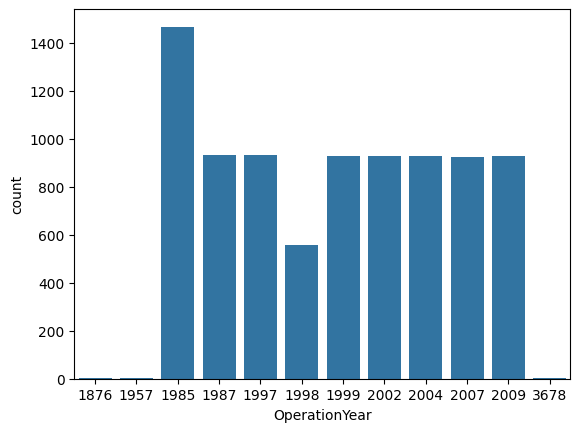

In [22]:
sns.barplot(df["OperationYear"].value_counts())

<Axes: ylabel='Category'>

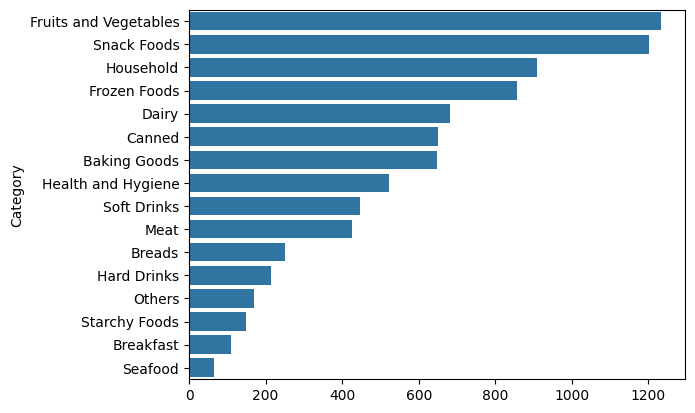

In [23]:
sns.barplot(x=df["Category"].value_counts().values, y=df["Category"].value_counts().index)

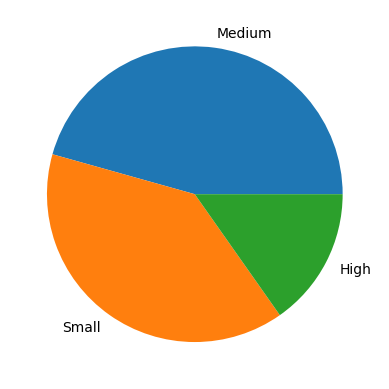

In [24]:
plt.pie(df["Size"].value_counts(), labels=df["Size"].value_counts().index)
plt.show()

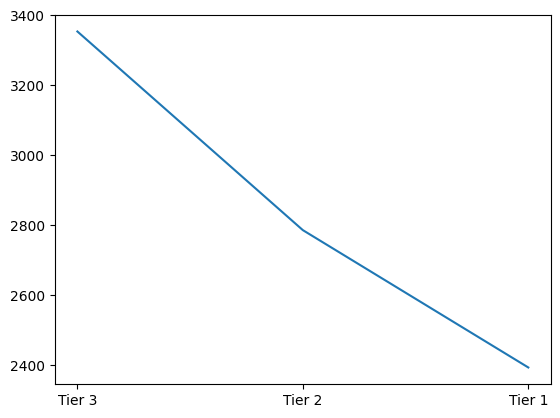

In [25]:
plt.plot(df["Area"].value_counts())
plt.show()

<Axes: xlabel='count', ylabel='Type'>

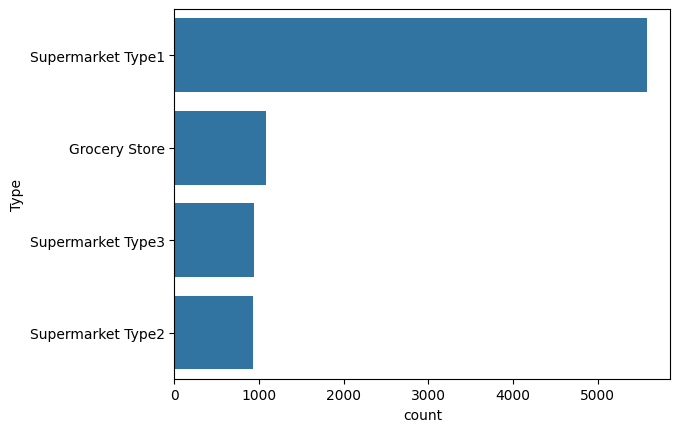

In [26]:
sns.barplot(x=df["Type"].value_counts(), y=df["Type"].value_counts().index)

<Axes: xlabel='Price', ylabel='Count'>

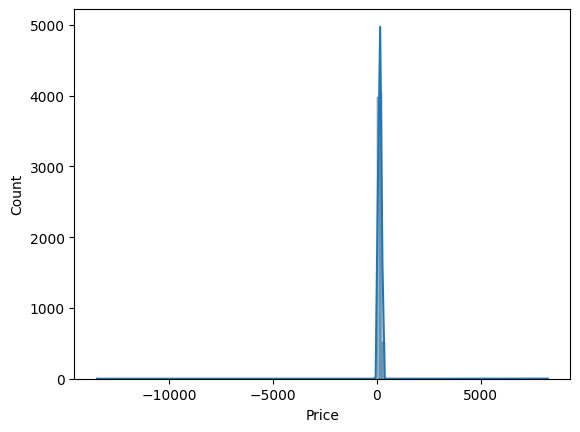

In [27]:
sns.histplot(df["Price"], kde=True)

<Axes: xlabel='Weight', ylabel='Count'>

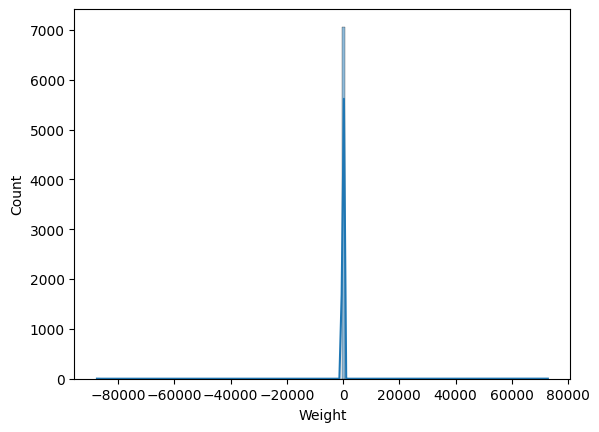

In [28]:
sns.histplot(df["Weight"], kde=True)

In [29]:
df.describe()

,No,Weight,Visibility,Price,OperationYear,Sales
count,8533.00,7067.00,8533.00,8533.00,8533.00,8533.00
mean,4268.50,24.17,9080.18,138.64,1998.00,2180.30
std,2465.26,1629.58,838768.77,218.32,20.07,1706.65
min,1.00,-87523.00,0.00,-13479.00,1876.00,33.29
25%,2134.00,8.77,0.03,93.78,1987.00,830.92
50%,4267.00,12.60,0.05,143.01,1999.00,1794.33
75%,6404.00,16.85,0.09,185.66,2004.00,3099.96
max,8540.00,72816.35,77480627.00,8224.00,3678.00,13086.96


<Axes: ylabel='Weight'>

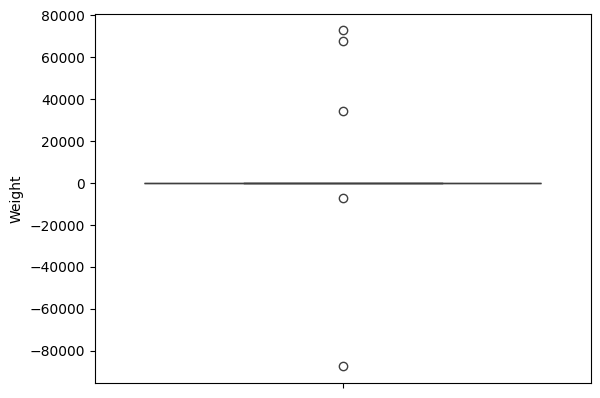

In [30]:
sns.boxplot(df["Weight"])

<Axes: ylabel='Price'>

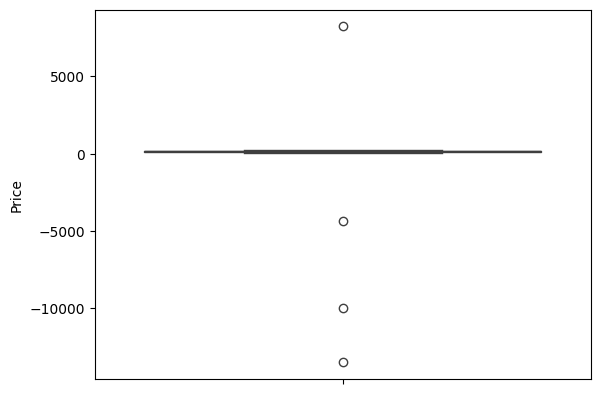

In [31]:
sns.boxplot(df["Price"])

<Axes: ylabel='StoreCode'>

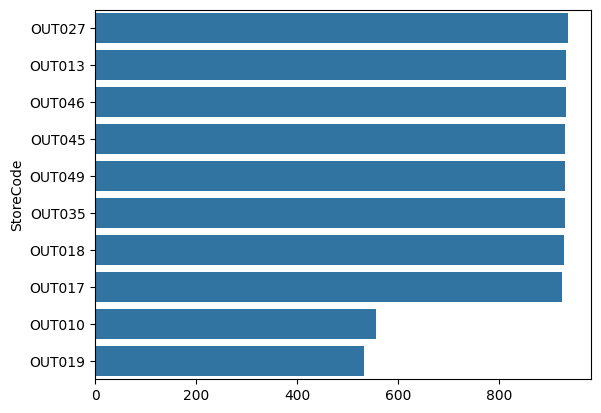

In [32]:
sns.barplot(x=df["StoreCode"].value_counts().values, y=df["StoreCode"].value_counts().index)

<Axes: ylabel='Visibility'>

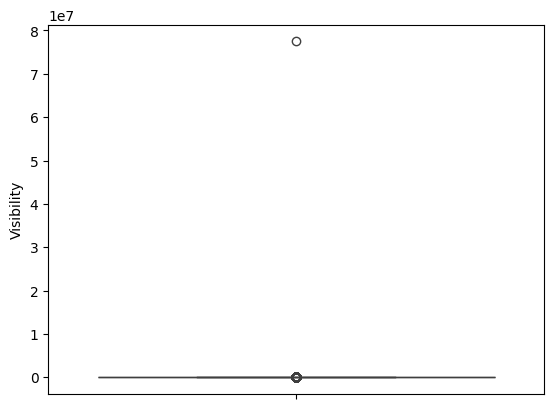

In [33]:
sns.boxplot(df["Visibility"])

#### Bi-Variate / Multi-Variate Analysis

In [34]:
df.sample(5)

,No,ID,Weight,Fat,Visibility,Category,Price,Security,StoreCode,OperationYear,Size,Area,Type,Sales
6477,6478,NCS30,5.95,LF,0.09,Household,127.87,Epic,OUT035,2004,Small,Tier 2,Supermarket Type1,2195.81
7488,7489,FDX57,17.25,Regular,0.05,Snack Foods,96.91,Allied Universal,OUT017,2007,NaN,Tier 2,Supermarket Type1,1458.10
2448,2449,FDE53,10.89,Low Fat,0.03,Frozen Foods,106.43,Allied Universal,OUT046,1997,Small,Tier 1,Supermarket Type1,1491.39
3957,3958,FDX59,10.20,Low Fat,0.05,Breads,35.36,Allied Universal,OUT018,2009,Medium,Tier 3,Supermarket Type2,237.69
2031,2032,FDX25,16.70,LF,0.10,Canned,184.03,Brinks,OUT046,1997,Small,Tier 1,Supermarket Type1,3101.30


<Axes: xlabel='Weight', ylabel='Sales'>

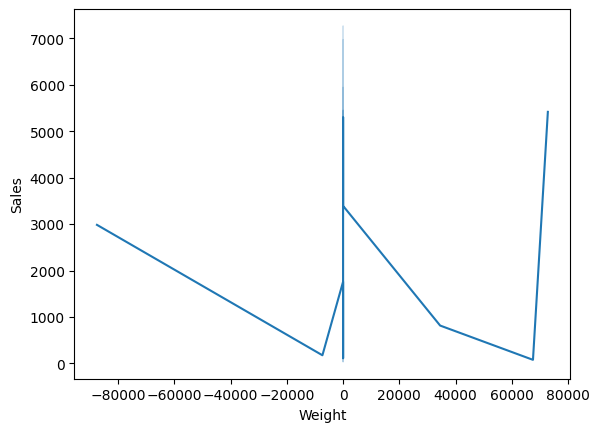

In [35]:
sns.lineplot(x=df["Weight"], y=df["Sales"])

<Axes: xlabel='Weight', ylabel='Sales'>

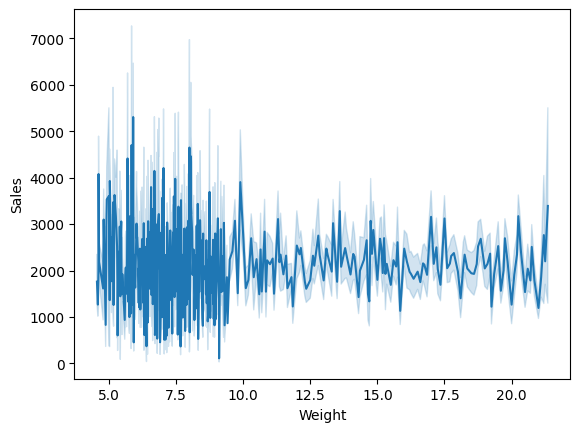

In [36]:
df_temp = df[df["Weight"] > 0]
df_temp = df_temp[df_temp["Weight"] < 100]
sns.lineplot(data=df_temp, x="Weight", y="Sales")
# Negative Weight need to remove
# Scaling is needed

<Axes: xlabel='Fat', ylabel='Sales'>

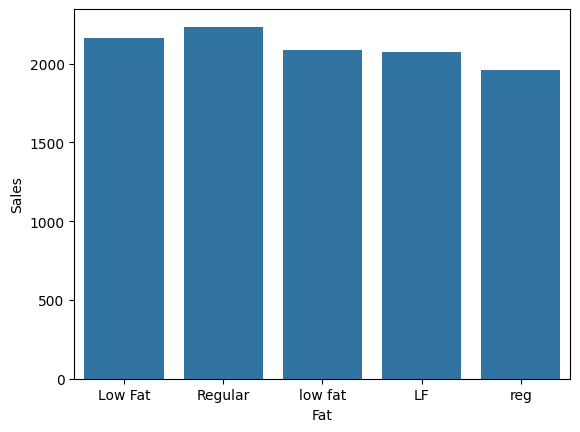

In [37]:
sns.barplot(data=df, x="Fat", y="Sales", errorbar=None)

#Low Fat + low fat Fat + LF and reg + regular need to combine

<Axes: xlabel='Fat', ylabel='Sales'>

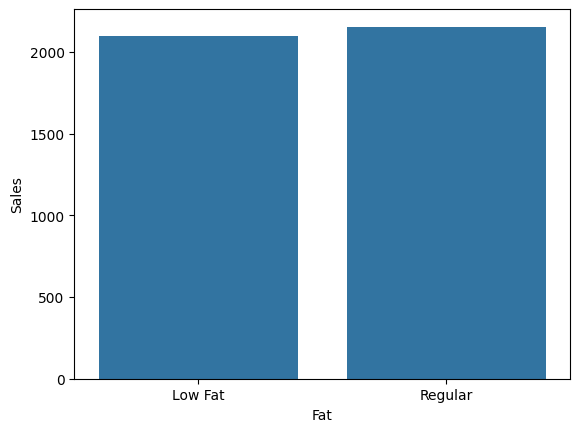

In [38]:
df_temp["Fat"] = df["Fat"].replace({
    "low fat": "Low Fat",
    "LF": "Low Fat",
    "reg": "Regular"
})

sns.barplot(data=df_temp, x="Fat", y="Sales", errorbar=None)

<Axes: xlabel='Visibility', ylabel='Sales'>

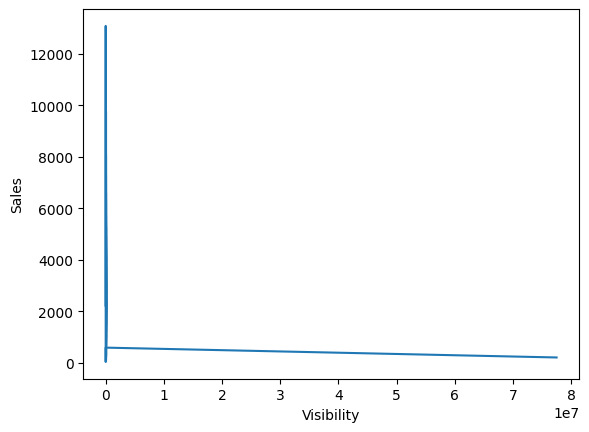

In [39]:
sns.lineplot(data=df, x="Visibility", y="Sales")

# Visibility contains large values need to remove

<Axes: xlabel='Visibility', ylabel='Sales'>

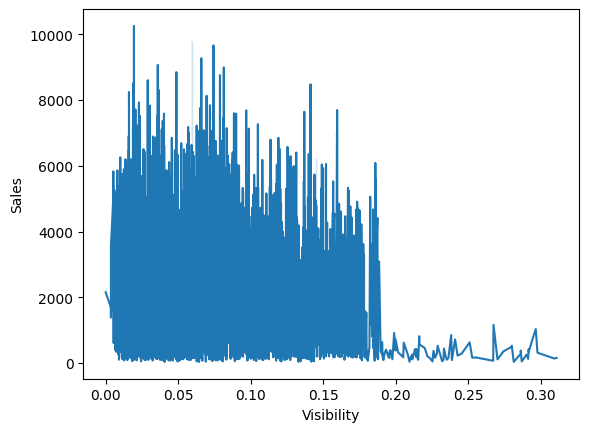

In [40]:
df_temp=df_temp[df_temp["Visibility"] < 10]
sns.lineplot(data=df_temp, x="Visibility", y="Sales")

<Axes: xlabel='Price', ylabel='Sales'>

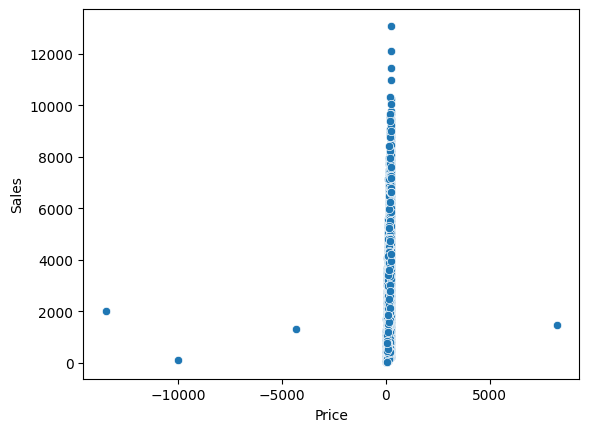

In [41]:
sns.scatterplot(data=df, x="Price", y="Sales")

<Axes: xlabel='Price', ylabel='Sales'>

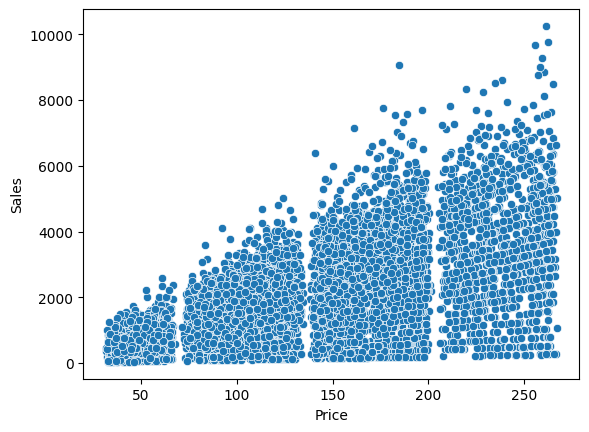

In [42]:
df_temp = df_temp[df_temp["Price"] > 0]
sns.scatterplot(data=df_temp, x="Price", y="Sales")

<Axes: xlabel='OperationYear', ylabel='Sales'>

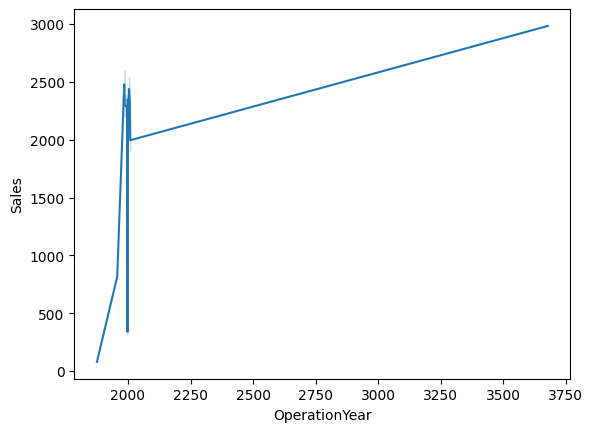

In [43]:
sns.lineplot(data=df, x="OperationYear", y="Sales")

<Axes: xlabel='OperationYear', ylabel='Sales'>

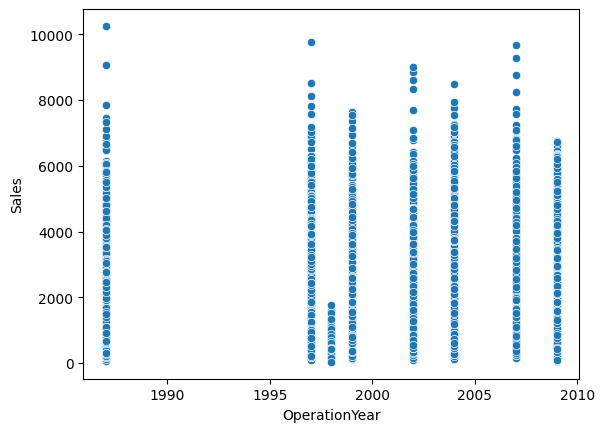

In [44]:
df_temp = df_temp[df_temp["OperationYear"] >= 1985]
df_temp = df_temp[df_temp["OperationYear"] <= 2026]
sns.scatterplot(data=df_temp, x="OperationYear", y="Sales")

In [45]:
df_temp.describe()

,No,Weight,Visibility,Price,OperationYear,Sales
count,7059.00,7059.00,7059.00,7059.00,7059.00,7059.00
mean,4252.68,12.86,0.06,141.24,2000.49,2118.68
std,2454.86,4.64,0.05,62.42,6.59,1533.55
min,1.00,4.55,0.00,31.49,1987.00,33.29
25%,2138.50,8.77,0.03,94.14,1997.00,922.80
50%,4230.00,12.60,0.05,142.75,2002.00,1789.67
75%,6371.50,16.85,0.09,186.02,2007.00,2966.14
max,8540.00,21.35,0.31,266.89,2009.00,10256.65


<Axes: xlabel='Area', ylabel='Sales'>

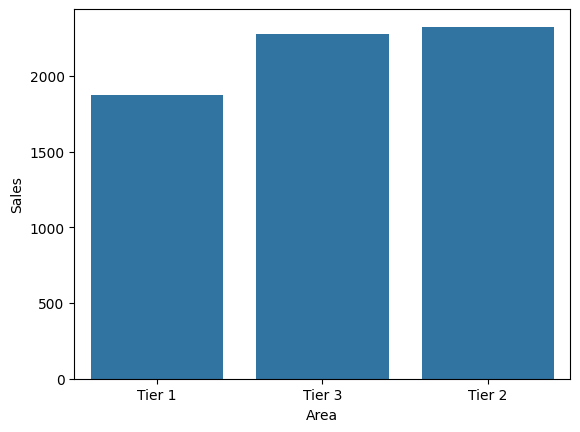

In [46]:
sns.barplot(data=df, x="Area", y="Sales", errorbar=None)

<Axes: xlabel='Sales', ylabel='Type'>

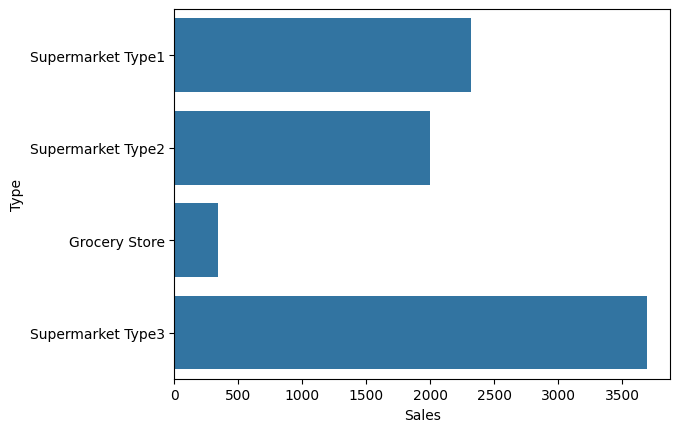

In [47]:
sns.barplot(data=df, y="Type", x="Sales", errorbar=None, orient="h")

<Axes: xlabel='Sales', ylabel='Category'>

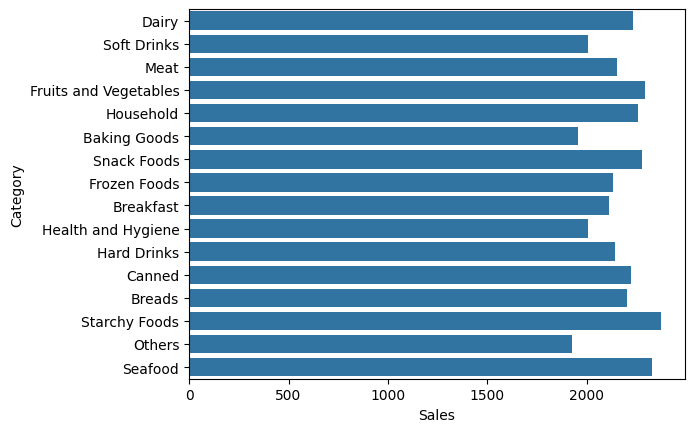

In [48]:
sns.barplot(data=df, y="Category", x="Sales", errorbar=None, orient="h")

<Axes: xlabel='Sales', ylabel='Size'>

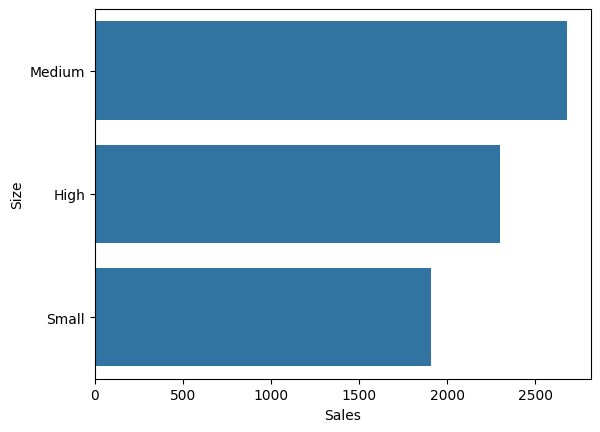

In [49]:
sns.barplot(data=df, y="Size", x="Sales", errorbar=None, orient="h")

<Axes: xlabel='Size', ylabel='count'>

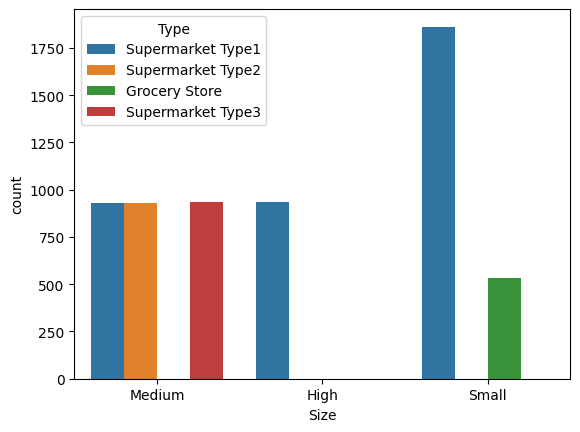

In [50]:
sns.countplot(data=df, x="Size", hue="Type")

<Axes: xlabel='Type', ylabel='count'>

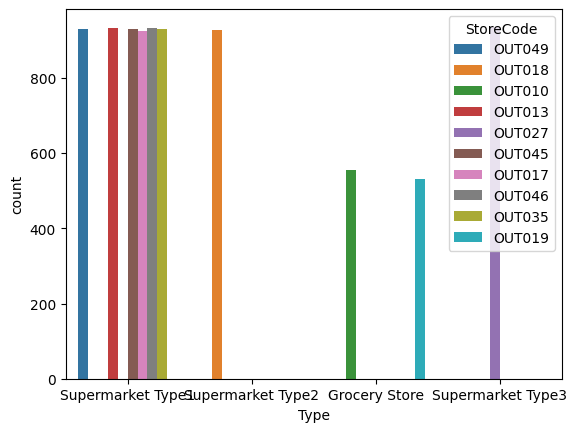

In [51]:
sns.countplot(data=df,x="Type", hue="StoreCode")

<Axes: xlabel='Type', ylabel='Sales'>

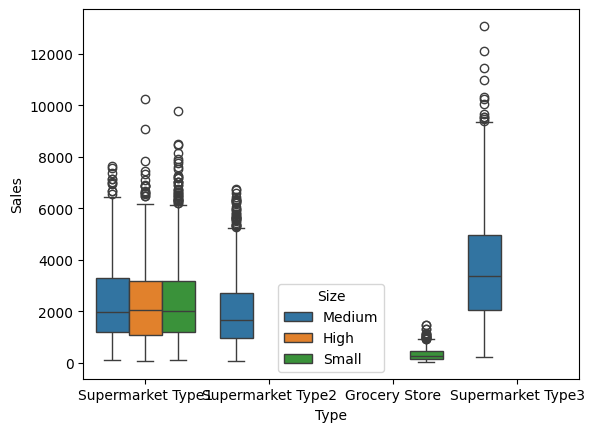

In [52]:
sns.boxplot( data=df, x="Type", y="Sales", hue="Size")

### Understanding the data

In [53]:
df.describe()

,No,Weight,Visibility,Price,OperationYear,Sales
count,8533.00,7067.00,8533.00,8533.00,8533.00,8533.00
mean,4268.50,24.17,9080.18,138.64,1998.00,2180.30
std,2465.26,1629.58,838768.77,218.32,20.07,1706.65
min,1.00,-87523.00,0.00,-13479.00,1876.00,33.29
25%,2134.00,8.77,0.03,93.78,1987.00,830.92
50%,4267.00,12.60,0.05,143.01,1999.00,1794.33
75%,6404.00,16.85,0.09,185.66,2004.00,3099.96
max,8540.00,72816.35,77480627.00,8224.00,3678.00,13086.96


In [54]:
df.sample(5)

,No,ID,Weight,Fat,Visibility,Category,Price,Security,StoreCode,OperationYear,Size,Area,Type,Sales
367,368,FDD44,8.05,Regular,0.08,Fruits and Vegetables,256.46,Allied Universal,OUT035,2004,Small,Tier 2,Supermarket Type1,5153.29
5124,5125,FDG57,14.70,Low Fat,0.07,Fruits and Vegetables,49.80,Prosegur,OUT035,2004,Small,Tier 2,Supermarket Type1,631.84
7426,7427,FDE39,7.89,Low Fat,0.04,Dairy,117.48,Epic,OUT035,2004,Small,Tier 2,Supermarket Type1,2026.03
6669,6670,FDN02,16.50,Low Fat,0.07,Canned,207.26,G4S,OUT035,2004,Small,Tier 2,Supermarket Type1,5383.66
8317,8318,FDH41,NaN,Low Fat,0.08,Frozen Foods,214.75,NSPS,OUT027,1985,Medium,Tier 3,Supermarket Type3,5806.44


In [55]:
df[df["Price"] <= 0].size

42

In [56]:
df[df["Weight"] <= 0].size

28

In [57]:
df[(df["Weight"] <= 0) & (df["Price"] <= 0)].size

0

In [58]:
df[(df["Weight"] <= 0) | (df["Price"] <= 0)].size

70

In [59]:
df.nlargest(5, "Visibility")

,No,ID,Weight,Fat,Visibility,Category,Price,Security,StoreCode,OperationYear,Size,Area,Type,Sales
3458,3459,FDQ27,NaN,Regular,77480627.00,Meat,101.40,Brinks,OUT019,1985,Small,Tier 1,Grocery Store,206.40
856,857,FDU13,NaN,low fat,0.33,Canned,146.04,Allied Universal,OUT019,1985,Small,Tier 1,Grocery Store,588.57
3757,3758,NCZ18,NaN,Low Fat,0.33,Household,252.77,Epic,OUT019,1985,Small,Tier 1,Grocery Store,761.01
1808,1809,FDJ56,NaN,Low Fat,0.32,Fruits and Vegetables,100.77,Brinks,OUT019,1985,Small,Tier 1,Grocery Store,199.74
7264,7265,FDT24,12.35,Regular,0.31,Baking Goods,79.23,G4S,OUT010,1998,NaN,Tier 3,Grocery Store,154.47


In [60]:
df_temp.describe()

,No,Weight,Visibility,Price,OperationYear,Sales
count,7059.00,7059.00,7059.00,7059.00,7059.00,7059.00
mean,4252.68,12.86,0.06,141.24,2000.49,2118.68
std,2454.86,4.64,0.05,62.42,6.59,1533.55
min,1.00,4.55,0.00,31.49,1987.00,33.29
25%,2138.50,8.77,0.03,94.14,1997.00,922.80
50%,4230.00,12.60,0.05,142.75,2002.00,1789.67
75%,6371.50,16.85,0.09,186.02,2007.00,2966.14
max,8540.00,21.35,0.31,266.89,2009.00,10256.65


In [61]:
df.nlargest(5, "Weight")

,No,ID,Weight,Fat,Visibility,Category,Price,Security,StoreCode,OperationYear,Size,Area,Type,Sales
536,537,FDY56,72816.35,Regular,0.06,Fruits and Vegetables,225.91,Prosegur,OUT046,1997,Small,Tier 1,Supermarket Type1,5416.95
3058,3059,NDL41,67523.00,Low Fat,0.12,Health and Hygiene,24.43,Epic,OUT019,1876,Small,Tier 1,Grocery Store,78.32
925,926,FDQ24,34510.00,Low Fat,0.05,Health and Hygiene,134.56,GardaWorld,OUT013,1957,High,Tier 3,Supermarket Type1,816.19
43,44,FDC02,21.35,Low Fat,0.07,Canned,259.93,AHS,OUT018,2009,Medium,Tier 3,Supermarket Type2,6768.52
484,485,FDC02,21.35,Low Fat,0.12,Canned,258.33,Epic,OUT010,1998,NaN,Tier 3,Grocery Store,520.66


In [62]:
df[df["OperationYear"] < 1985]

,No,ID,Weight,Fat,Visibility,Category,Price,Security,StoreCode,OperationYear,Size,Area,Type,Sales
925,926,FDQ24,34510.00,Low Fat,0.05,Health and Hygiene,134.56,GardaWorld,OUT013,1957,High,Tier 3,Supermarket Type1,816.19
3058,3059,NDL41,67523.00,Low Fat,0.12,Health and Hygiene,24.43,Epic,OUT019,1876,Small,Tier 1,Grocery Store,78.32


In [63]:
(df["Size"]).value_counts()

Size
Medium    2794
Small     2394
High       933
Name: count, dtype: int64

In [64]:
(df["Size"])

0       Medium
1       Medium
2       Medium
3          NaN
4         High
         ...  
8535      High
8536       NaN
8537     Small
8538    Medium
8539     Small
Name: Size, Length: 8533, dtype: object

In [65]:
df["ID"].unique()

array(['FDA15', 'DRC01', 'FDN15', ..., 'NCW30', 'NCW05', 'FDY78'],
      shape=(1561,), dtype=object)

In [66]:
pattern = r"^[A-Z]{3}\d{2}$"

df["ID"].str.match(pattern).all()

np.True_

### Train-Test Split

In [67]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(df.drop("Sales", axis=1), df["Sales"], test_size=0.2, random_state=42)

df.shape, X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

((8533, 14), (6826, 13), (1707, 13), (6826,), (1707,))

### Machine Learning Pipeline

#### 1.) Finding Useful Features

In [68]:
df.sample(1)

,No,ID,Weight,Fat,Visibility,Category,Price,Security,StoreCode,OperationYear,Size,Area,Type,Sales
5619,5620,DRA59,8.27,Regular,0.00,Soft Drinks,183.29,AHS,OUT017,2007,NaN,Tier 2,Supermarket Type1,2406.20


In [69]:
from sklearn.preprocessing import FunctionTransformer

trf1 = FunctionTransformer(
    lambda x: x.drop(columns=["No", "Security"])
)

X_train_temp = trf1.fit_transform(X_train)
X_train_temp.sample(1)

,ID,Weight,Fat,Visibility,Category,Price,StoreCode,OperationYear,Size,Area,Type
6126,FDN23,6.58,Regular,0.08,Breads,146.04,OUT013,1987,High,Tier 3,Supermarket Type1


#### 2.) Segregation of ID column

In [70]:
def split_id(X):
    X = X.copy()
    X[["Product_Code", "Product_ID"]] = X["ID"].str.extract(
        r"^([A-Z]{3})(\d{2})$"
    )
    X["Product_ID"] = pd.to_numeric(
        X["Product_ID"], errors="coerce"
    )
    X = X.drop(columns=["ID"])
    return X
    
trf2 = FunctionTransformer(split_id)

X_train_temp = trf2.fit_transform(X_train_temp)
X_train_temp.sample(5)

,Weight,Fat,Visibility,Category,Price,StoreCode,OperationYear,Size,Area,Type,Product_Code,Product_ID
6126,6.58,Regular,0.08,Breads,146.04,OUT013,1987,High,Tier 3,Supermarket Type1,FDN,23
7096,13.10,Low Fat,0.04,Fruits and Vegetables,173.81,OUT017,2007,NaN,Tier 2,Supermarket Type1,FDI,45
3913,8.37,Low Fat,0.07,Hard Drinks,37.95,OUT046,1997,Small,Tier 1,Supermarket Type1,DRK,35
1411,20.25,Regular,0.01,Dairy,191.52,OUT046,1997,Small,Tier 1,Supermarket Type1,FDD,40
7191,7.76,Low Fat,0.06,Snack Foods,98.77,OUT013,1987,High,Tier 3,Supermarket Type1,FDD,58


#### 3) Handing Numerical Features

In [71]:
trf3 = FunctionTransformer(
    lambda X: X.assign(
        Weight=np.where(
            (X["Weight"] > 0) & (X["Weight"] <= 100),
            X["Weight"],
            np.nan
        ),
        Visibility=np.where(
            (X["Visibility"] >= 0) & (X["Visibility"] <= 1.0),
            X["Visibility"],
            np.nan
        ),
        Price=np.where(
            (X["Price"] > 0) & (X["Price"] < 1000),
            X["Price"],
            np.nan
        ),
        OperationYear=np.clip(X["OperationYear"], 1985, pd.Timestamp.today().year)
    )
)

X_train_temp = trf3.fit_transform(X_train_temp)
X_train_temp.shape, X_train.shape

((6826, 12), (6826, 13))

In [72]:
X_train_temp.describe()

,Weight,Visibility,Price,OperationYear,Product_ID
count,5668.00,6825.00,6824.00,6826.00,6826.00
mean,12.88,0.07,141.45,1997.86,30.27
std,4.66,0.05,62.17,8.38,17.18
min,4.55,0.00,24.43,1985.00,1.00
25%,8.77,0.03,94.48,1987.00,16.00
50%,12.60,0.05,143.38,1999.00,30.00
75%,17.00,0.09,186.24,2004.00,45.00
max,21.35,0.33,266.89,2026.00,78.00


#### 4) Handling Categorical Features

In [73]:
trf4 = FunctionTransformer(
    lambda X: X.assign(
        Fat=X["Fat"].replace({
            "low fat": "Low Fat",
            "LF": "Low Fat",
            "reg": "Regular"
        }),
        StoreCode=X["StoreCode"].astype("string")
            .str.extract(r"OUT(\d+)", expand=False)
            .astype("Int64")
    )
)

X_train_temp = trf4.fit_transform(X_train_temp)
X_train_temp.sample(5)

,Weight,Fat,Visibility,Category,Price,StoreCode,OperationYear,Size,Area,Type,Product_Code,Product_ID
3969,8.43,Low Fat,0.02,Soft Drinks,197.98,46,1997,Small,Tier 1,Supermarket Type1,DRE,48
7328,19.60,Low Fat,0.02,Household,107.00,35,2004,Small,Tier 2,Supermarket Type1,NCC,7
439,20.70,Regular,0.05,Dairy,213.49,49,1999,Medium,Tier 1,Supermarket Type1,FDL,51
6031,20.75,Low Fat,0.03,Health and Hygiene,150.47,49,1999,Medium,Tier 1,Supermarket Type1,NCA,5
7068,19.00,Low Fat,0.07,Snack Foods,132.96,46,1997,Small,Tier 1,Supermarket Type1,FDM,34


#### 5) Handling Missing Values

In [74]:
X_train_temp.describe()

,Weight,Visibility,Price,StoreCode,OperationYear,Product_ID
count,5668.00,6825.00,6824.00,6826.00,6826.00,6826.00
mean,12.88,0.07,141.45,29.05,1997.86,30.27
std,4.66,0.05,62.17,13.98,8.38,17.18
min,4.55,0.00,24.43,10.00,1985.00,1.00
25%,8.77,0.03,94.48,17.00,1987.00,16.00
50%,12.60,0.05,143.38,27.00,1999.00,30.00
75%,17.00,0.09,186.24,45.00,2004.00,45.00
max,21.35,0.33,266.89,49.00,2026.00,78.00


In [75]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

trf5 = ColumnTransformer(
    transformers = [
        # Handling Missing values on Numerical Features
        ('trf_5_1', SimpleImputer(strategy="median"), ["Weight", "Visibility", "Price", "StoreCode", "Product_ID"]),
        # Handling Missing values on Categorical Features
        ('trf_5_2', SimpleImputer(strategy="most_frequent"), ["Fat", "Category", "Area", "Size", "Type", "Product_Code"])
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)
trf5.set_output(transform="pandas")

X_train_temp = trf5.fit_transform(X_train_temp)
X_train_temp.sample()

,Weight,Visibility,Price,StoreCode,Product_ID,Fat,Category,Area,Size,Type,Product_Code,OperationYear
1673,12.60,0.07,254.10,19.00,6.00,Low Fat,Household,Tier 1,Small,Grocery Store,NCQ,1985


#### 6) Appling Encoding (One Hot and Ordinal)

In [76]:
categorical_cols = X_train_temp.select_dtypes(
    include=["object", "category", "string"]
).columns
for col in categorical_cols:
    print(f"{col}: {X_train_temp[col].unique()}")

Fat: ['Low Fat' 'Regular']
Category: ['Household' 'Snack Foods' 'Fruits and Vegetables' 'Frozen Foods' 'Dairy'
 'Meat' 'Canned' 'Baking Goods' 'Soft Drinks' 'Health and Hygiene'
 'Breads' 'Hard Drinks' 'Seafood' 'Breakfast' 'Others' 'Starchy Foods']
Area: ['Tier 2' 'Tier 3' 'Tier 1']
Size: ['Medium' 'High' 'Small']
Type: ['Supermarket Type1' 'Supermarket Type2' 'Grocery Store'
 'Supermarket Type3']
Product_Code: ['NCJ' 'FDN' 'FDY' 'FDD' 'DRJ' 'FDK' 'FDI' 'FDZ' 'FDE' 'DRD' 'FDT' 'FDU'
 'NCW' 'NCK' 'NCZ' 'FDJ' 'DRK' 'FDV' 'FDP' 'NCR' 'FDG' 'FDS' 'NCV' 'FDA'
 'FDH' 'FDC' 'DRG' 'FDW' 'NCP' 'DRC' 'FDO' 'NCM' 'DRO' 'NCN' 'FDQ' 'NCS'
 'NCX' 'NCB' 'DRL' 'NCD' 'FDR' 'FDM' 'NCI' 'FDF' 'FDL' 'NCQ' 'FDB' 'NCL'
 'FDX' 'NCH' 'NCE' 'NCO' 'NCF' 'DRI' 'DRA' 'DRM' 'DRH' 'NCC' 'DRE' 'NCT'
 'NCA' 'NCU' 'DRF' 'DRN' 'NCG' 'DRZ' 'DRP' 'NCY' 'DRB' 'DRQ' 'DRY' 'NDL']


In [77]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

trf6 = ColumnTransformer(
    transformers = [
        # Applying Encoding on Categorical Features
        ('trf_6_1', OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), ['Category', 'Product_Code','Type']),
        ('trf_6_2', OrdinalEncoder(categories = [['Low Fat', 'Regular'], 
                                                 ['Tier 1', 'Tier 2', 'Tier 3'],
                                                ['Small', 'Medium', 'High']],
             handle_unknown="use_encoded_value", unknown_value=-1), 
         ['Fat', 'Area', 'Size']
        ),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)
trf6.set_output(transform="pandas")

X_train_temp = trf6.fit_transform(X_train_temp)
X_train_temp.sample()

,Category_Breads,Category_Breakfast,Category_Canned,Category_Dairy,Category_Frozen Foods,Category_Fruits and Vegetables,Category_Hard Drinks,Category_Health and Hygiene,Category_Household,Category_Meat,...,Type_Supermarket Type3,Fat,Area,Size,Weight,Visibility,Price,StoreCode,Product_ID,OperationYear
1519,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,...,0.00,0.00,2.00,1.00,18.10,0.04,95.51,10.00,57.00,1998


#### 7) Scaling all the features

In [78]:
X_train.describe()

,No,Weight,Visibility,Price,OperationYear
count,6826.00,5673.00,6826.00,6826.00,6826.00
mean,4270.02,26.96,11350.88,141.98,1998.08
std,2451.88,1818.83,937799.47,127.91,22.05
min,1.00,-87523.00,0.00,-4327.00,1876.00
25%,2157.25,8.77,0.03,94.48,1987.00
50%,4260.50,12.60,0.05,143.38,1999.00
75%,6382.75,17.00,0.09,186.28,2004.00
max,8538.00,72816.35,77480627.00,8224.00,3678.00


In [79]:
from sklearn.preprocessing import StandardScaler

trf7 = ColumnTransformer(
    transformers=[
        ("trf_7_1", StandardScaler(), ["Weight", "Visibility", "Price"])
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)
trf7.set_output(transform="pandas")

X_train_temp = trf7.fit_transform(X_train_temp)
X_train_temp.describe()

,Weight,Visibility,Price,Category_Breads,Category_Breakfast,Category_Canned,Category_Dairy,Category_Frozen Foods,Category_Fruits and Vegetables,Category_Hard Drinks,...,Product_Code_NDL,Type_Supermarket Type1,Type_Supermarket Type2,Type_Supermarket Type3,Fat,Area,Size,StoreCode,Product_ID,OperationYear
count,6826.00,6826.00,6826.00,6826.00,6826.00,6826.00,6826.00,6826.00,6826.00,6826.00,...,6826.00,6826.00,6826.00,6826.00,6826.00,6826.00,6826.00,6826.00,6826.00,6826.00
mean,0.00,0.00,-0.00,0.03,0.01,0.07,0.08,0.10,0.15,0.03,...,0.00,0.66,0.11,0.11,0.35,1.10,0.83,29.05,30.27,1997.86
std,1.00,1.00,1.00,0.17,0.11,0.26,0.27,0.30,0.36,0.16,...,0.01,0.47,0.31,0.31,0.48,0.82,0.60,13.98,17.18,8.38
min,-1.95,-1.27,-1.88,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,10.00,1.00,1985.00
25%,-0.83,-0.75,-0.76,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,17.00,16.00,1987.00
50%,-0.05,-0.24,0.03,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,1.00,0.00,0.00,0.00,1.00,1.00,27.00,30.00,1999.00
75%,0.77,0.55,0.72,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,1.00,0.00,0.00,1.00,2.00,1.00,45.00,45.00,2004.00
max,2.01,5.04,2.02,1.00,1.00,1.00,1.00,1.00,1.00,1.00,...,1.00,1.00,1.00,1.00,1.00,2.00,2.00,49.00,78.00,2026.00


#### 8) Applying Machine Learning Models

In [80]:
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet,
    BayesianRidge
)
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1, max_iter=10000),
    "Elastic Net": ElasticNet(alpha=0.1, max_iter=10000),
    "Bayesian Ridge": BayesianRidge(),
    "KNN": KNeighborsRegressor(n_neighbors=5)
}

#### 9) Pipeline Implementation and Model Fit

In [81]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone

preprocessing = Pipeline([
    ("trf1", trf1),
    ("trf2", trf2),
    ("trf3", trf3),
    ("trf4", trf4),
    ("trf5", trf5),
    ("trf6", trf6),
    ("trf7", trf7)
])

def build_model_pipeline(model):
    return Pipeline([
        ("preprocessing", clone(preprocessing)),
        ("model", clone(model))
    ])

In [82]:
from sklearn.model_selection import cross_val_score

results = []
trained_pipelines = {}

for name, model in models.items():
    model_pipe = build_model_pipeline(model)

    scores = cross_val_score(
        model_pipe,
        X_train,
        Y_train,
        cv=5,
        scoring="r2",
        n_jobs=1
    )

    results.append({
        "Model": name,
        "CV_R2": scores.mean()
    })

    trained_pipelines[name] = model_pipe

results_df = pd.DataFrame(results).sort_values(
    "CV_R2", ascending=False
)

display(results_df.round(4))

C:\Users\simra\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\simra\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\simra\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\simra\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\simra\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Foun

,Model,CV_R2
4,Bayesian Ridge,0.56
2,Lasso,0.56
1,Ridge,0.55
0,Linear Regression,0.55
3,Elastic Net,0.50
5,KNN,0.45


#### 10) Model Testing and Evaluation

In [83]:
# Y_pred = pipe.predict(X_test)

In [84]:
# Select the model with the lowest cross-validation MAE
best_model_name = results_df.iloc[0]["Model"]
best_pipeline = trained_pipelines[best_model_name]

print("Best model:", best_model_name)
print("Best CV R2:", results_df.iloc[0]["CV_R2"])

Best model: Bayesian Ridge
Best CV R2: 0.5555607672442557


In [85]:
# Fit the selected pipeline on all training data
best_pipeline.fit(X_train, Y_train)

,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,steps,"[('trf1', ...), ('trf2', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,func,<function <la...0022C23B7D760>
,inverse_func,None
,validate,False


In [86]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Y_pred = best_pipeline.predict(X_test)

print("Selected model:", best_model_name)
print("MAE:", mean_absolute_error(Y_test, Y_pred))
print("RMSE:", np.sqrt(mean_squared_error(Y_test, Y_pred)))
print("R2:", r2_score(Y_test, Y_pred))

Selected model: Bayesian Ridge
MAE: 828.9491256111243
RMSE: 1141.3938358125367
R2: 0.5610349520761828


##### - Comparison between test and train prediction

In [88]:
train_pred = best_pipeline.predict(X_train)

print("Train R2:", r2_score(Y_train, train_pred))
print("Test R2:", r2_score(Y_test, Y_pred))

Train R2: 0.5660576684959089
Test R2: 0.5610349520761828
